# Лабораторная работа №3 — Визуализация данных

**Студент:** Фадеев А. М.  **Группа:** 6401

**Датасет:** Poker Tournament Survivorship — https://www.kaggle.com/datasets/sergionefedov/poker-tournament-survivorship

Используется тот же набор, что в лабораторной работе №2: 45 000 игроков в турнирный покер, шкалы подготовки и дисциплины, параметры игровой практики и три целевых признака — непрерывный `realized_roi`, бинарные `went_broke` и `profitable`.

Очищенная версия из ЛР2 отдельным файлом не сохранялась, поэтому ячейка подготовки повторяет базовую очистку: приведение типов, обработка пропусков, удаление дубликатов и создание порядковых признаков `skill_band`, `stake_level`, `volume_band`.

**Запуск в Google Colab:** загрузите этот ноутбук в Colab и выберите «Среда выполнения → Выполнить все». Когда появится запрос, выберите файл `data/poker_raw.csv` из папки лабораторной на компьютере. Файл нужно загружать заново после сброса среды Colab. При локальном запуске файл автоматически читается из папки `data`. Исходный CSV использует разделитель `;`.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import plotly.express as px
import plotly.io as pio

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+notebook_connected"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titlelocation"] = "left"
plt.rcParams["axes.grid.axis"] = "y"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

DATA_DIR = "data"
RAW_PATH = Path(DATA_DIR) / "poker_raw.csv"
MISSING_TOKENS = ["unknown", "no_data", "-"]
TO_NUMERIC = ["skill", "tilt_control", "study_hours_week", "bankroll_buyins"]

MAIN = "#2d6a9f"
ACCENT = "#c2572b"
NEUTRAL = "#8a9099"
SKILL_COLORS = ["#9ecae1", "#4292c6", "#2166ac", "#08306b"]
VOLUME_COLORS = ["#fdd0a2", "#fd8d3c", "#d94801", "#7f2704"]

print("pandas:", pd.__version__, "| seaborn:", sns.__version__,
      "| matplotlib:", plt.matplotlib.__version__, "| plotly:", plotly.__version__)

## Подготовка данных: повторная очистка по ЛР2

In [2]:
# В Colab локальные файлы компьютера недоступны до загрузки.
if not RAW_PATH.is_file():
    if IN_COLAB:
        from google.colab import files

        print("Выберите исходный файл poker_raw.csv из папки data лабораторной работы.")
        uploaded = files.upload()
        if "poker_raw.csv" not in uploaded:
            raise FileNotFoundError("Загрузите именно файл poker_raw.csv и запустите ячейку ещё раз.")
        RAW_PATH.parent.mkdir(parents=True, exist_ok=True)
        RAW_PATH.write_bytes(uploaded["poker_raw.csv"])
    else:
        raise FileNotFoundError(f"Не найден {RAW_PATH}. Поместите poker_raw.csv в папку data.")

df = pd.read_csv(RAW_PATH, sep=";", na_values=MISSING_TOKENS, encoding="utf-8-sig")
required_columns = {
    "player_id", "skill", "bankroll_mgmt", "tilt_control", "study_hours_week",
    "tournaments_played", "avg_field_size", "avg_buyin", "bankroll_buyins",
    "itm_rate", "final_table_rate", "win_rate", "biggest_cash_x",
    "final_bankroll_bi", "realized_roi", "went_broke", "profitable",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(
        f"В файле {RAW_PATH} отсутствуют столбцы: {', '.join(sorted(missing_columns))}. "
        "Проверьте, что загружен исходный poker_raw.csv с разделителем ';'. "
        f"Найдены столбцы: {list(df.columns)}"
    )
for col in TO_NUMERIC:
    df[col] = pd.to_numeric(df[col], errors="coerce")

base = list(df.columns)
rows_raw = len(df)
df = df.dropna(subset=base, thresh=len(base) - 1).copy()
for col in ["study_hours_week", "bankroll_buyins"]:
    df[col] = df[col].fillna(df[col].median())
for col in ["skill", "tilt_control"]:
    df[col] = df[col].fillna(df[col].mean())
df["bankroll_buyins"] = df["bankroll_buyins"].round().astype("int64")
duplicates = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

df["skill_band"] = pd.cut(df["skill"], bins=[0, 3, 5, 7, 10],
                          labels=["новичок", "любитель", "регуляр", "профи"],
                          include_lowest=True, ordered=True)
df["stake_level"] = pd.cut(df["avg_buyin"], bins=[0, 25, 100, 500, np.inf],
                           labels=["micro", "low", "mid", "high"], right=False, ordered=True)
df["volume_band"] = pd.qcut(df["tournaments_played"], q=4,
                            labels=["очень малый", "малый", "средний", "большой"])
df["discipline_index"] = ((df["bankroll_mgmt"] + df["tilt_control"]) / 2).round(2)
df["venue"] = pd.cut(df["avg_field_size"], bins=[0, 120, 600, np.inf],
                     labels=["live_series", "hybrid", "online_mtt"], right=False)
for col in ["went_broke", "profitable"]:
    df[col] = df[col].astype("category")

print("строк:", rows_raw, "->", len(df), "| удалено дубликатов:", duplicates)
print("пропусков:", int(df.isnull().sum().sum()), "| столбцов:", df.shape[1])
print(df[["player_id", "skill", "skill_band", "avg_buyin", "stake_level",
          "tournaments_played", "volume_band", "venue", "realized_roi"]].head(3).to_string(index=False))

## Занятие 1. Статическая визуализация: Matplotlib и Seaborn

### Часть 1. Визуализация распределений

### Задание 1.1. Распределение числового признака

Признак для анализа — `realized_roi`, целевая переменная набора: фактический ROI игрока за выборку в процентах. Выбран потому, что именно его распределение объясняет главный вопрос датасета — почему результат на короткой дистанции определяется дисперсией.

Число интервалов гистограммы выбирается по **правилу Фридмана–Дьякониса**: ширина интервала `h = 2 · IQR / n^(1/3)`, число интервалов — размах, делённый на `h`. Правило опирается на межквартильный размах, поэтому устойчиво к выбросам — в отличие от правила Стёрджеса, которое ориентировано на нормальное распределение и для 44 777 наблюдений с тяжёлым правым хвостом даёт слишком грубую картину. Оба значения считаются ниже и сравниваются.

In [3]:
roi = df["realized_roi"]
q1, q3 = roi.quantile([0.25, 0.75])
iqr = q3 - q1
h_fd = 2 * iqr / len(roi) ** (1 / 3)
bins_fd = int(np.ceil((roi.max() - roi.min()) / h_fd))
bins_sturges = int(np.ceil(np.log2(len(roi)) + 1))

print("n:", len(roi), "| IQR:", round(iqr, 2), "| ширина интервала по Фридману-Дьяконису:", round(h_fd, 2))
print("интервалов по Фридману-Дьяконису:", bins_fd, "| по Стёрджесу:", bins_sturges)
print("перекос:", round(roi.skew(), 2), "| куртозис:", round(roi.kurtosis(), 2))
print("среднее:", round(roi.mean(), 2), "| медиана:", round(roi.median(), 2),
      "| std:", round(roi.std(), 2))

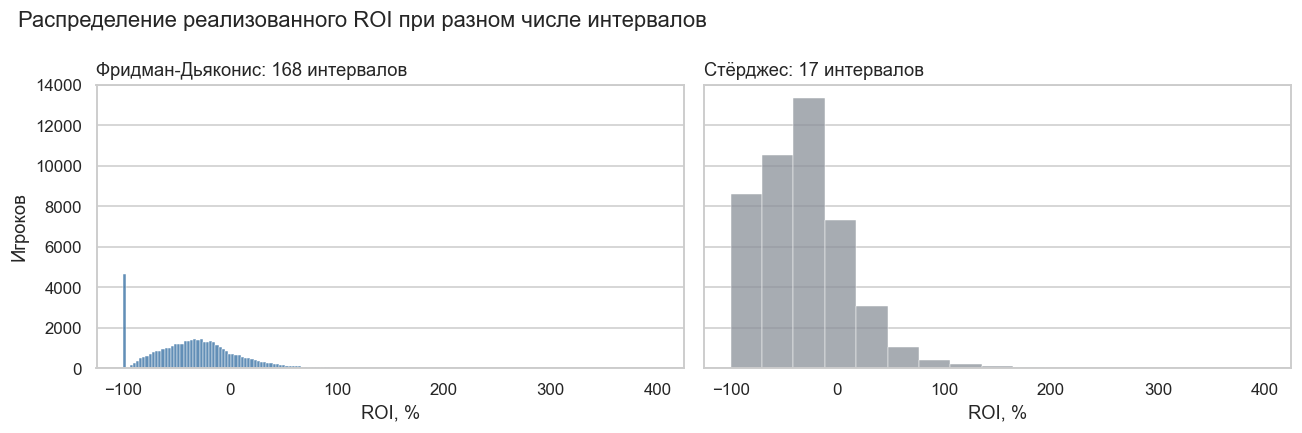

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(roi, bins=bins_fd, color=MAIN, edgecolor="white", linewidth=0.3, ax=axes[0])
axes[0].set_title(f"Фридман-Дьяконис: {bins_fd} интервалов")
axes[0].set_xlabel("ROI, %")
axes[0].set_ylabel("Игроков")

sns.histplot(roi, bins=bins_sturges, color=NEUTRAL, edgecolor="white", linewidth=0.3, ax=axes[1])
axes[1].set_title(f"Стёрджес: {bins_sturges} интервалов")
axes[1].set_xlabel("ROI, %")

fig.suptitle("Распределение реализованного ROI при разном числе интервалов", x=0.02, ha="left")
fig.tight_layout()
plt.show()

Крупные интервалы Стёрджеса скрывают пик у −100%: столбец шириной около 29 п.п. сливает обанкротившихся игроков с теми, кто просто закончил в минусе. Дальше используется разбиение по Фридману–Дьяконису.

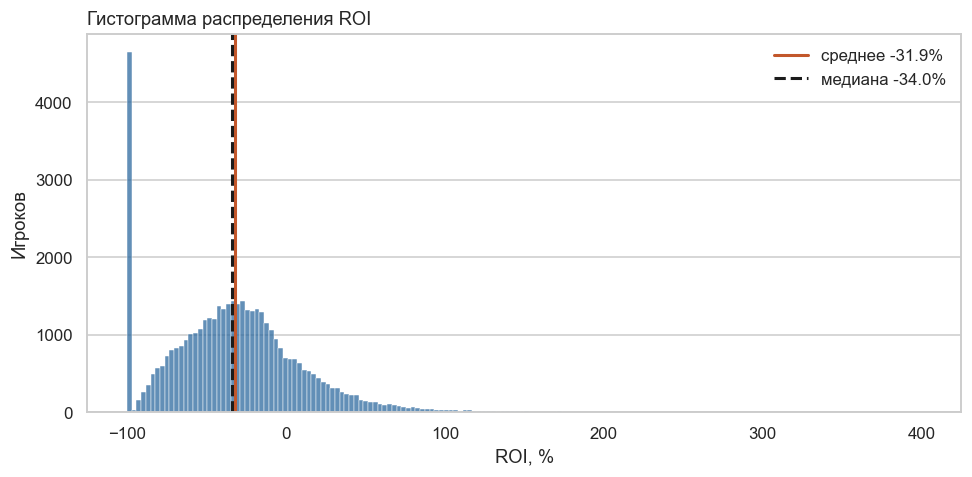

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))

sns.histplot(roi, bins=bins_fd, color=MAIN, edgecolor="white", linewidth=0.3, ax=ax)
ax.axvline(roi.mean(), color=ACCENT, linewidth=2, label=f"среднее {roi.mean():.1f}%")
ax.axvline(roi.median(), color="#1b1b1b", linewidth=2, linestyle="--",
           label=f"медиана {roi.median():.1f}%")
ax.set_title("Гистограмма распределения ROI")
ax.set_xlabel("ROI, %")
ax.set_ylabel("Игроков")
ax.legend(frameon=False)

fig.tight_layout()
plt.show()

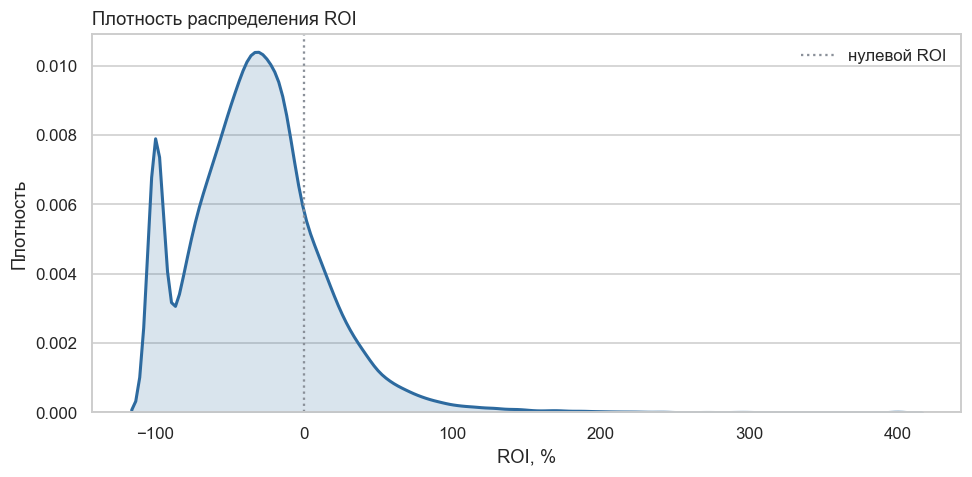

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))

sns.kdeplot(roi, color=MAIN, linewidth=2, fill=True, alpha=0.18, ax=ax)
ax.axvline(0, color=NEUTRAL, linewidth=1.5, linestyle=":", label="нулевой ROI")
ax.set_title("Плотность распределения ROI")
ax.set_xlabel("ROI, %")
ax.set_ylabel("Плотность")
ax.legend(frameon=False)

fig.tight_layout()
plt.show()

print("доля игроков с ROI > 0:", round((roi > 0).mean() * 100, 2), "%")
print("доля игроков с ROI = -100%:", round((roi == -100).mean() * 100, 2), "%")

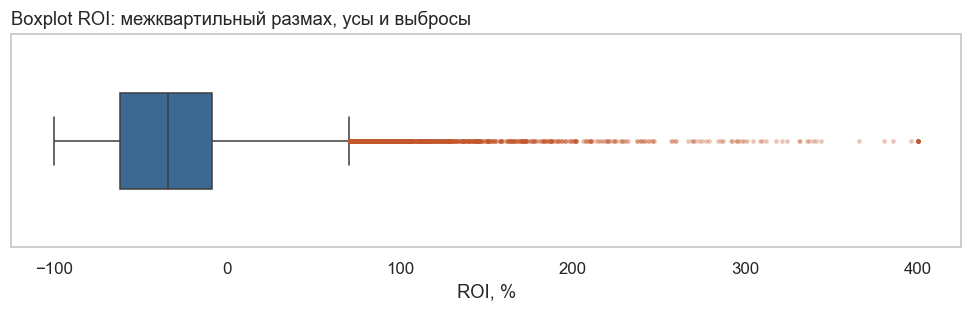

In [7]:
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = roi[(roi < lower) | (roi > upper)]

fig, ax = plt.subplots(figsize=(9, 3))

sns.boxplot(x=roi, color=MAIN, width=0.45, fliersize=3,
            flierprops={"marker": "o", "markerfacecolor": ACCENT,
                        "markeredgecolor": "none", "alpha": 0.35}, ax=ax)
ax.set_title("Boxplot ROI: межквартильный размах, усы и выбросы")
ax.set_xlabel("ROI, %")

fig.tight_layout()
plt.show()

print("Q1:", round(q1, 2), "| медиана:", round(roi.median(), 2), "| Q3:", round(q3, 2),
      "| IQR:", round(iqr, 2))
print("границы усов:", round(lower, 2), "...", round(upper, 2))
print("выбросов:", len(outliers), f"({len(outliers) / len(roi) * 100:.2f}%)",
      "| снизу:", int((roi < lower).sum()), "| сверху:", int((roi > upper).sum()))
print("максимум:", roi.max(), "| 95-й процентиль:", round(roi.quantile(0.95), 1),
      "| 99-й процентиль:", round(roi.quantile(0.99), 1))

**Вывод.** Распределение ROI скошено вправо: большинство игроков в минусе, редкие крупные выигрыши образуют длинный хвост.

### Часть 2. Визуализация сравнений

### Задание 1.2. Средний ROI по уровню мастерства

Берётся группировка из ЛР2 по `skill_band`: средний `realized_roi` в четырёх группах мастерства. Сравнение средних между категориями — задача для столбчатой диаграммы: длина столбца от нуля прямо кодирует величину. Порядок столбцов задан порядком категорий от новичка к профи, а не значением, потому что признак порядковый. Вертикальные отрезки — 95%-ные доверительные интервалы среднего.

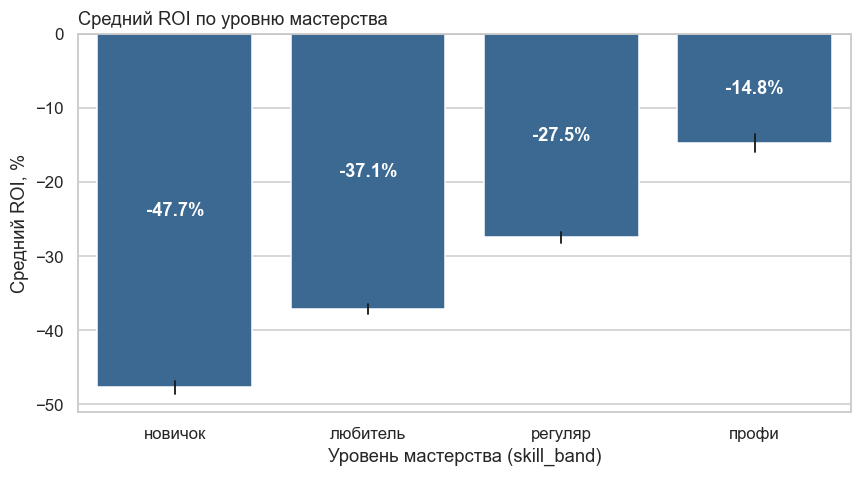

In [8]:
by_skill = df.groupby("skill_band", observed=True).agg(
    игроков=("player_id", "count"),
    средний_roi=("realized_roi", "mean"),
    медианный_roi=("realized_roi", "median"),
    доля_прибыльных=("profitable", lambda s: s.astype(int).mean() * 100),
).round(2)
print(by_skill.to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))

sns.barplot(data=df, x="skill_band", y="realized_roi", estimator="mean",
            errorbar=("ci", 95), color=MAIN, err_kws={"color": "#1b1b1b", "linewidth": 1.2}, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.1f%%", label_type="center", color="white", fontweight="bold")
ax.axhline(0, color="#1b1b1b", linewidth=1)
ax.set_title("Средний ROI по уровню мастерства")
ax.set_xlabel("Уровень мастерства (skill_band)")
ax.set_ylabel("Средний ROI, %")

fig.tight_layout()
plt.show()

print("разрыв профи - новичок:",
      round(by_skill.loc["профи", "средний_roi"] - by_skill.loc["новичок", "средний_roi"], 2), "п.п.")

**Вывод.** Средний ROI монотонно растёт с уровнем мастерства.

### Задание 1.3. Сгруппированный barplot: мастерство × объём

Сводная таблица из ЛР2 — средний ROI в разрезе двух категориальных признаков: `skill_band` и `volume_band` (четыре квартильные группы по числу сыгранных турниров). Внутри каждой группы мастерства столбцы упорядочены по объёму, цвет — последовательная шкала от светлого (малый объём) к тёмному (большой), потому что объём тоже порядковый.

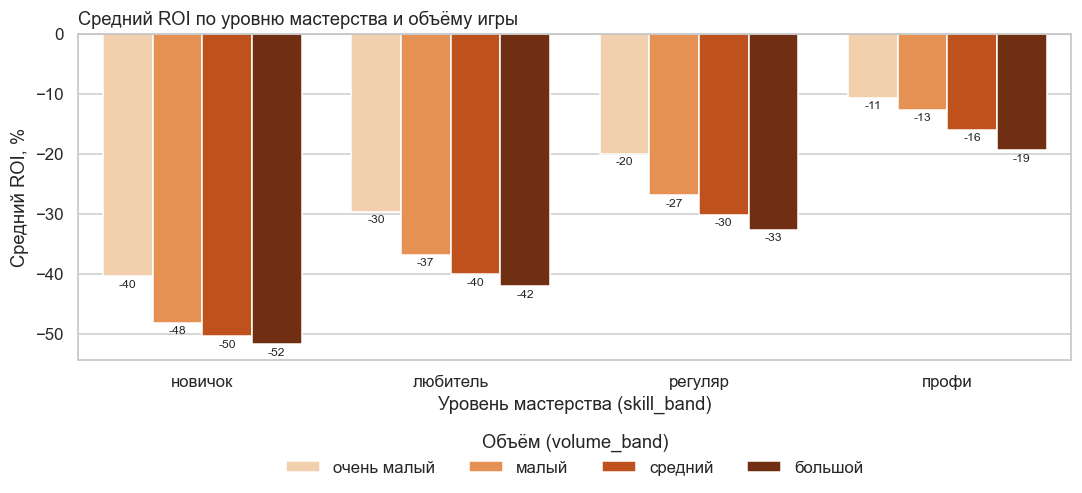

In [9]:
pivot_roi = pd.pivot_table(df, index="skill_band", columns="volume_band", values="realized_roi",
                           aggfunc="mean", observed=True).round(2)
print(pivot_roi.to_string())

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(data=df, x="skill_band", y="realized_roi", hue="volume_band", estimator="mean",
            errorbar=None, palette=VOLUME_COLORS, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2, fontsize=8)
ax.axhline(0, color="#1b1b1b", linewidth=1)
ax.set_title("Средний ROI по уровню мастерства и объёму игры")
ax.set_xlabel("Уровень мастерства (skill_band)")
ax.set_ylabel("Средний ROI, %")
ax.legend(title="Объём (volume_band)", frameon=False, ncols=4, loc="lower center",
          bbox_to_anchor=(0.5, -0.4))

fig.tight_layout()
plt.show()

print("падение ROI от очень малого к большому объёму:")
print((pivot_roi["большой"] - pivot_roi["очень малый"]).round(2).to_string())

**Вывод.** Более высокий объём игры связан с более низким средним ROI во всех группах мастерства.

### Часть 3. Визуализация взаимосвязей

### Задание 1.4. Диаграмма рассеяния: объём и ROI с цветом по мастерству

По оси X — `tournaments_played`, по оси Y — `realized_roi`, цвет — `skill_band`. Ось X логарифмическая: объём меняется от 10 до 1 567 турниров, и в линейной шкале 75% точек сжались бы в левой пятой части графика. Из 44 777 точек отображается случайная выборка в 4 000 с полупрозрачностью: на полном наборе точки перекрывают друг друга и плотность не читается.

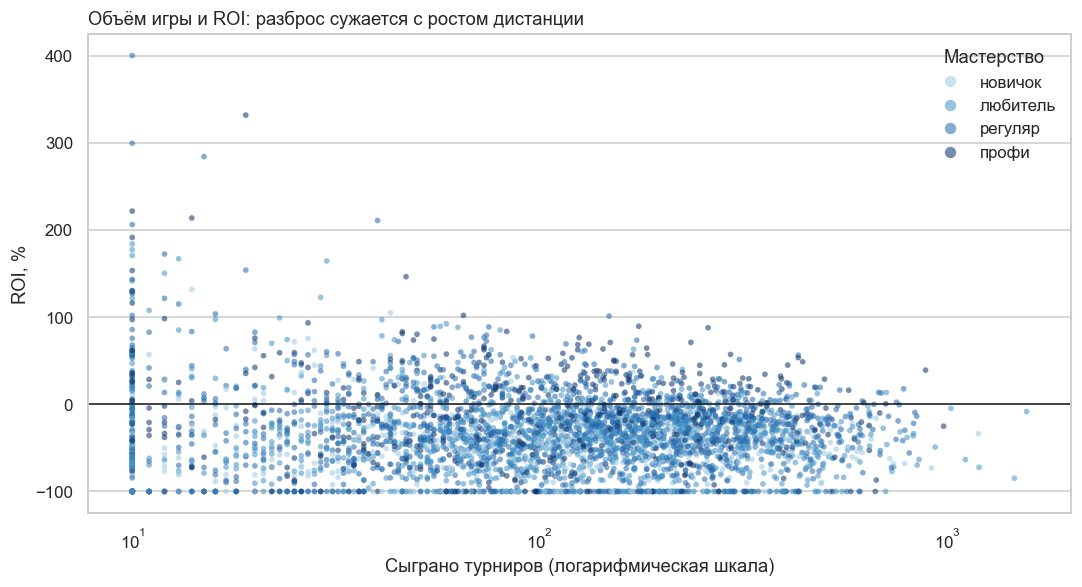

In [10]:
sample = df.sample(4000, random_state=6401)

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.scatterplot(data=sample, x="tournaments_played", y="realized_roi", hue="skill_band",
                palette=SKILL_COLORS, s=14, alpha=0.55, linewidth=0, ax=ax)
ax.set_xscale("log")
ax.axhline(0, color="#1b1b1b", linewidth=1)
ax.set_title("Объём игры и ROI: разброс сужается с ростом дистанции")
ax.set_xlabel("Сыграно турниров (логарифмическая шкала)")
ax.set_ylabel("ROI, %")
ax.legend(title="Мастерство", frameon=False, markerscale=2)

fig.tight_layout()
plt.show()

print(df.groupby("volume_band", observed=True).agg(
    турниров=("tournaments_played", lambda s: f"{s.min()}-{s.max()}"),
    разброс_roi=("realized_roi", "std"),
    доля_roi_выше_100=("realized_roi", lambda s: (s > 100).mean() * 100),
    доля_roi_минус_100=("realized_roi", lambda s: (s == -100).mean() * 100),
).round(2).to_string())
print("корреляция объёма и ROI:", round(df["tournaments_played"].corr(df["realized_roi"]), 3))

**Вывод.** С ростом числа турниров разброс ROI заметно сужается.

### Задание 1.5. Тепловая карта корреляций

В матрицу входят все 14 исходных количественных признаков и два бинарных целевых (`went_broke`, `profitable`, приведены к 0/1 — для бинарной переменной коэффициент Пирсона равен точечно-бисериальному). Производный `discipline_index` исключён: он по построению среднее двух других столбцов и добавил бы тривиальную корреляцию. Показан нижний треугольник — матрица симметрична, верхняя половина дублирует нижнюю. Шкала расходящаяся с центром в нуле: синий — положительная связь, красный — отрицательная, белый — её отсутствие.

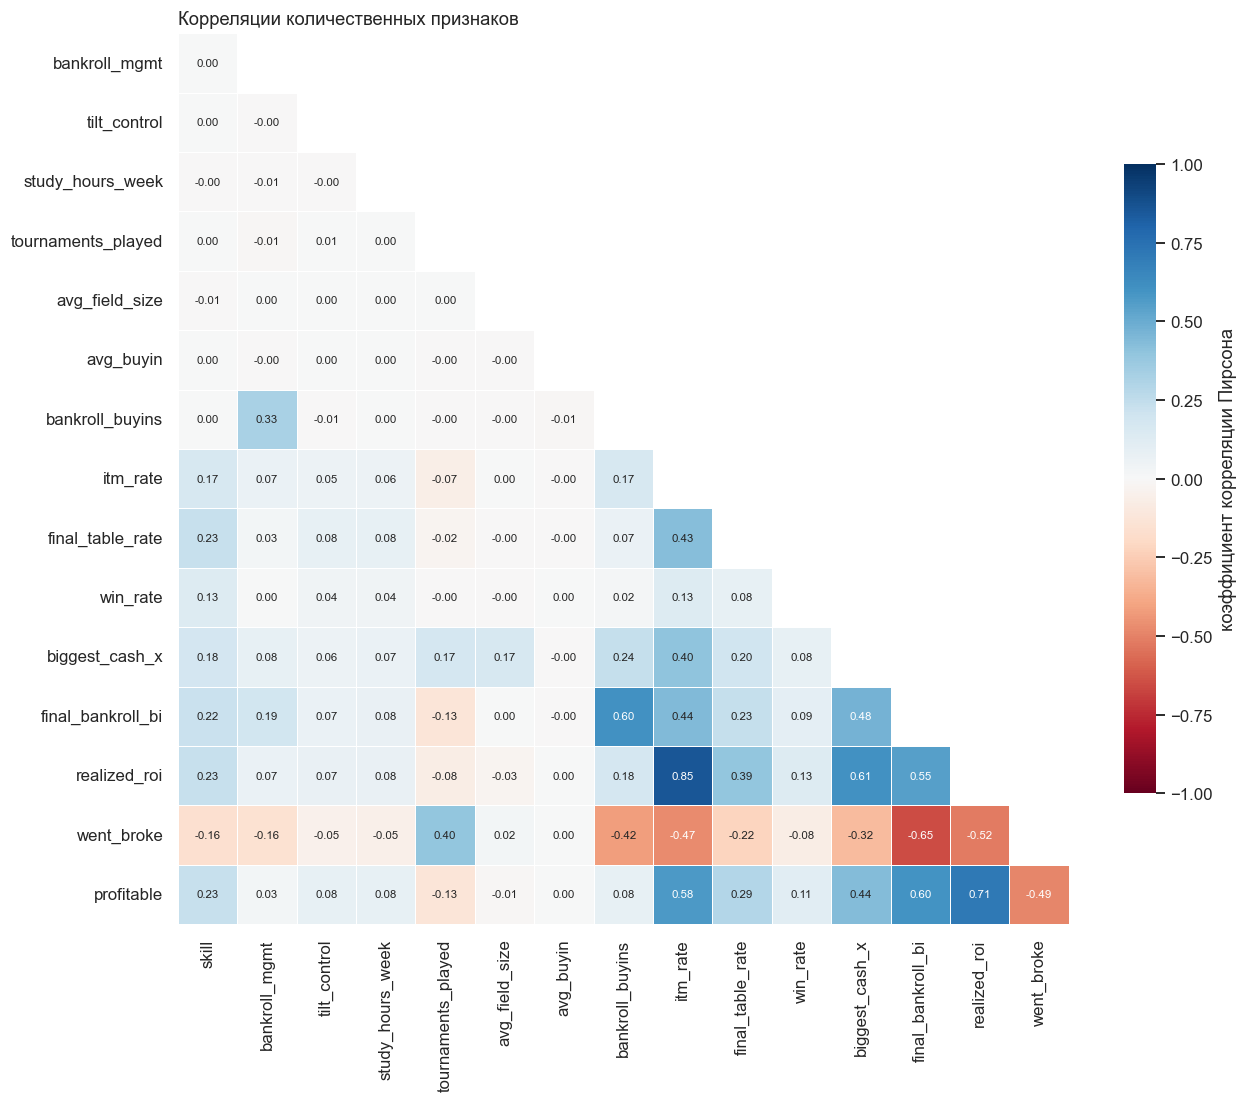

In [11]:
corr_cols = ["skill", "bankroll_mgmt", "tilt_control", "study_hours_week", "tournaments_played",
             "avg_field_size", "avg_buyin", "bankroll_buyins", "itm_rate", "final_table_rate",
             "win_rate", "biggest_cash_x", "final_bankroll_bi", "realized_roi"]
corr = df[corr_cols].assign(went_broke=df["went_broke"].astype(int),
                            profitable=df["profitable"].astype(int)).corr()
corr_view = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(corr_view, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(corr_view, mask=mask, cmap="RdBu", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7.5}, linewidths=0.5, linecolor="white", square=True,
            cbar_kws={"shrink": 0.7, "label": "коэффициент корреляции Пирсона"}, ax=ax)
ax.set_title("Корреляции количественных признаков")
ax.grid(False)

fig.tight_layout()
plt.show()

pairs = (corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack()
         .rename("r").reset_index().rename(columns={"level_0": "признак_1", "level_1": "признак_2"}))
pairs["|r|"] = pairs["r"].abs()
print(pairs.sort_values("|r|", ascending=False).head(8).round(3).to_string(index=False))
print()
print("корреляции с realized_roi:")
print(corr["realized_roi"].drop("realized_roi").sort_values(ascending=False).round(3).to_string())

**Вывод.** Самая сильная связь с ROI наблюдается у доли попаданий в деньги (ITM).

## Занятие 2. Интерактивная визуализация и типичные ошибки

### Часть 1. Типичные ошибки визуализации

### Задание 2.1. Три типичные ошибки

**1. Искажение масштаба оси Y.** Столбчатая диаграмма кодирует величину длиной столбца, поэтому её ось обязана начинаться с нуля. Если обрезать ось, например начать её с 49 вместо 0, то разница 2 п.п. превращается в столбцы, отличающиеся по высоте в десять раз. Числа на оси при этом остаются верными, но глаз сравнивает длины, а не подписи, и читатель уходит с ложным выводом о сильном различии. Обрезка допустима для линейного графика и точечной диаграммы, где значение кодируется положением точки, а не длиной, — но тогда это нужно явно обозначить. Ниже — «плохой» и «исправленный» варианты на одних и тех же данных.

**2. Неверный выбор типа графика.** Тип графика выбирается по задаче: распределение — гистограмма, плотность, boxplot; сравнение — столбцы; взаимосвязь — рассеяние, тепловая карта; динамика — линия. Классическая ошибка — круговая диаграмма для признака с большим числом категорий. Человек плохо сравнивает углы и площади секторов, особенно не соседних; при 10 и более категориях соседние секторы почти одинаковы, мелкие сливаются, подписи наползают друг на друга, а порядок категорий (если признак порядковый) теряется по кругу. Та же информация на отсортированной столбчатой диаграмме читается сразу. Иллюстрация — второй пример ниже, на признаке `study_hours_week` с 16 значениями.

**3. Перегруженность графика.** Любой элемент, не несущий данных, отнимает внимание у данных: 3D-эффекты (перспектива искажает длины — ближний столбец кажется больше дальнего равного), тени, градиенты, раскраска каждого столбца в свой цвет без смысла, густая сетка, рамки, дублирующие подписи. Обратная сторона той же ошибки — отсутствие нужного: нет подписей осей, единиц измерения, заголовка, легенды. Принцип Тафти: максимизировать долю «чернил данных» — убрать всё, без чего график не теряет смысла, и оставить всё, без чего его нельзя прочесть. На этом наборе такая ошибка возникла бы, если бы в задании 1.3 каждому из 16 столбцов дали свой случайный цвет вместо последовательной шкалы объёма: цвет перестал бы кодировать признак и только мешал бы.

**Пример 1. Обрезанная ось Y — «плохой» и «исправленный» варианты.** Данные — доля игроков, обнуливших банкролл, по типу площадки `venue`.

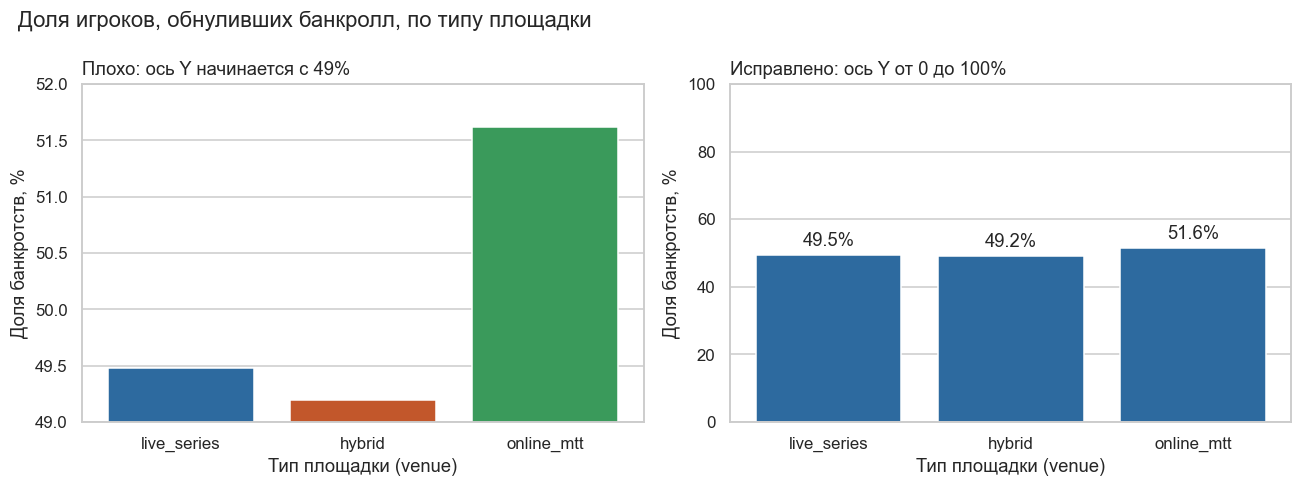

In [12]:
broke_by_venue = (df.groupby("venue", observed=True)["went_broke"]
                  .apply(lambda s: s.astype(int).mean() * 100).round(2))
print(broke_by_venue.to_string())
print("разница максимум - минимум:", round(broke_by_venue.max() - broke_by_venue.min(), 2), "п.п.",
      "| отношение:", round(broke_by_venue.max() / broke_by_venue.min(), 3))

labels = broke_by_venue.index.astype(str)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(labels, broke_by_venue.values, color=[MAIN, ACCENT, "#3a9a5b"])
axes[0].set_ylim(49, 52)
axes[0].set_title("Плохо: ось Y начинается с 49%")
axes[0].set_ylabel("Доля банкротств, %")

axes[1].bar(labels, broke_by_venue.values, color=MAIN)
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%", padding=3)
axes[1].set_ylim(0, 100)
axes[1].set_title("Исправлено: ось Y от 0 до 100%")
axes[1].set_ylabel("Доля банкротств, %")
axes[1].set_xlabel("Тип площадки (venue)")
axes[0].set_xlabel("Тип площадки (venue)")

fig.suptitle("Доля игроков, обнуливших банкролл, по типу площадки", x=0.02, ha="left")
fig.tight_layout()
plt.show()

**Вывод.** Обрезанная шкала Y визуально сильно преувеличивает различия между площадками.

**Пример 2. Круговая диаграмма для признака с большим числом категорий.** Данные — распределение игроков по часам изучения покера в неделю (`study_hours_week`, округлено до целого, 15 и более часов объединены), 16 категорий.

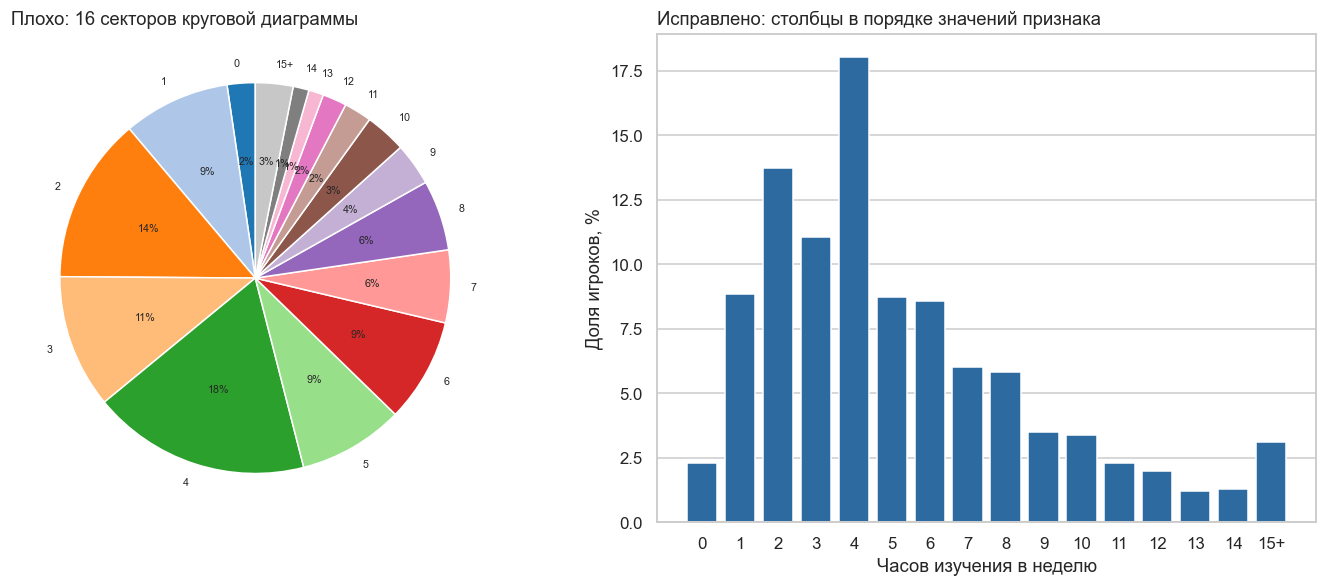

In [13]:
hours = df["study_hours_week"].round().clip(upper=15).astype(int)
hours_counts = hours.value_counts().sort_index()
hours_labels = [f"{h}" if h < 15 else "15+" for h in hours_counts.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].pie(hours_counts.values, labels=hours_labels, autopct="%.0f%%", textprops={"fontsize": 7},
            colors=sns.color_palette("tab20", len(hours_counts)), startangle=90)
axes[0].set_title("Плохо: 16 секторов круговой диаграммы")

axes[1].bar(hours_labels, hours_counts.values / len(df) * 100, color=MAIN)
axes[1].set_title("Исправлено: столбцы в порядке значений признака")
axes[1].set_xlabel("Часов изучения в неделю")
axes[1].set_ylabel("Доля игроков, %")

fig.tight_layout()
plt.show()

print((hours_counts / len(df) * 100).round(2).rename(index=dict(zip(hours_counts.index, hours_labels))).to_string())

**Вывод.** Столбчатая диаграмма читается лучше круговой при большом числе категорий.

### Часть 2. Динамика и интерактивная визуализация в Plotly

### Задание 2.2. Интерактивная диаграмма рассеяния

Временного признака в наборе нет: каждая строка — итог игрока за всю выборку, дат турниров нет. Поэтому строится интерактивная диаграмма рассеяния `px.scatter`: доля попаданий в деньги `itm_rate` против `realized_roi` — пара с самой сильной корреляцией из задания 1.5, цвет — уровень мастерства. При наведении на точку всплывает подсказка с идентификатором игрока и семью признаками одновременно. Отображается случайная выборка в 3 000 игроков.

In [14]:
scatter_df = df.sample(3000, random_state=6401).assign(
    банкрот=lambda d: d["went_broke"].map({1: "да", 0: "нет"}).astype(str),
    skill_band=lambda d: d["skill_band"].astype(str),
)

fig_scatter = px.scatter(
    scatter_df, x="itm_rate", y="realized_roi", color="skill_band",
    category_orders={"skill_band": ["новичок", "любитель", "регуляр", "профи"]},
    color_discrete_sequence=SKILL_COLORS, opacity=0.65,
    hover_name="player_id",
    hover_data={"skill": ":.2f", "tournaments_played": True, "bankroll_buyins": True,
                "biggest_cash_x": ":.1f", "final_bankroll_bi": ":.1f", "банкрот": True,
                "itm_rate": ":.1f", "realized_roi": ":.1f", "skill_band": False},
    labels={"itm_rate": "Попаданий в деньги, %", "realized_roi": "ROI, %",
            "skill_band": "Мастерство", "skill": "skill", "tournaments_played": "турниров",
            "bankroll_buyins": "банкролл, BI", "biggest_cash_x": "крупнейший занос, x",
            "final_bankroll_bi": "итоговый банкролл, BI"},
    title="Доля попаданий в деньги и ROI",
    template="plotly_white", height=520,
)
fig_scatter.update_traces(marker={"size": 6})
fig_scatter.add_hline(y=0, line_color="#1b1b1b", line_width=1)
fig_scatter.show()

print(df.groupby(pd.cut(df["itm_rate"], [0, 5, 10, 15, 20, 60], include_lowest=True), observed=True)
      .agg(игроков=("player_id", "count"), средний_roi=("realized_roi", "mean"),
           доля_прибыльных=("profitable", lambda s: s.astype(int).mean() * 100)).round(2).to_string())
print("игроков с itm_rate = 0:", int((df["itm_rate"] == 0).sum()),
      "| их ROI:", df.loc[df["itm_rate"] == 0, "realized_roi"].unique())

**Вывод.** Более высокая доля попаданий в деньги связана с более высоким ROI.

### Задание 2.3. Интерактивная столбчатая диаграмма с сортировкой

Категории — 16 комбинаций мастерства и объёма игры, показатель — доля игроков, обнуливших банкролл. Цвет кодирует объём той же последовательной шкалой, что в задании 1.3. Кнопки над графиком переключают порядок столбцов: по убыванию показателя, по возрастанию или в исходном порядке категорий. Подсказка при наведении показывает число игроков, долю банкротств, средний ROI и долю прибыльных.

In [15]:
groups = (df.groupby(["skill_band", "volume_band"], observed=True)
          .agg(игроков=("player_id", "count"),
               доля_банкротств=("went_broke", lambda s: s.astype(int).mean() * 100),
               средний_roi=("realized_roi", "mean"),
               доля_прибыльных=("profitable", lambda s: s.astype(int).mean() * 100))
          .round(2).reset_index())
groups["группа"] = groups["skill_band"].astype(str) + " · " + groups["volume_band"].astype(str)
groups["volume_band"] = groups["volume_band"].astype(str)
original_order = groups["группа"].tolist()

fig_bar = px.bar(
    groups, x="группа", y="доля_банкротств", color="volume_band",
    category_orders={"volume_band": ["очень малый", "малый", "средний", "большой"],
                     "группа": original_order},
    color_discrete_sequence=VOLUME_COLORS,
    hover_data={"игроков": True, "доля_банкротств": ":.1f", "средний_roi": ":.1f",
                "доля_прибыльных": ":.1f", "volume_band": False, "группа": False},
    labels={"группа": "Мастерство · объём", "доля_банкротств": "Доля банкротств, %",
            "volume_band": "Объём", "средний_roi": "средний ROI, %",
            "доля_прибыльных": "доля прибыльных, %"},
    text="доля_банкротств",
    title="Доля обнулившихся игроков по мастерству и объёму игры",
    template="plotly_white", height=540,
)
fig_bar.update_traces(texttemplate="%{text:.0f}", textposition="outside")
fig_bar.update_layout(
    yaxis_range=[0, 105], xaxis_tickangle=-40, margin={"t": 110},
    updatemenus=[{
        "type": "buttons", "direction": "right", "x": 0, "xanchor": "left", "y": 1.13, "yanchor": "bottom",
        "buttons": [
            {"label": "По убыванию", "method": "relayout",
             "args": [{"xaxis.categoryorder": "total descending"}]},
            {"label": "По возрастанию", "method": "relayout",
             "args": [{"xaxis.categoryorder": "total ascending"}]},
            {"label": "Исходный порядок", "method": "relayout",
             "args": [{"xaxis.categoryorder": "array", "xaxis.categoryarray": original_order}]},
        ],
    }],
)
fig_bar.show()

print(groups.sort_values("доля_банкротств", ascending=False)
      [["группа", "игроков", "доля_банкротств", "средний_roi", "доля_прибыльных"]].to_string(index=False))

**Вывод.** Доля банкротств различается между группами мастерства и объёма игры.

## Часть 3. Итоговая визуальная сводка

### Задание 2.4. Визуальная сводка по датасету

Шесть графиков, которые вместе описывают набор: форму целевой переменной, два главных фактора результата (мастерство и объём), фактор риска банкротства (банкролл), структуру связей между признаками и поведение отдельных игроков. Динамики среди задач нет: в наборе нет временного признака, роль «времени» частично играет длина дистанции `tournaments_played`.

#### График 1. Распределение ROI — *распределение*

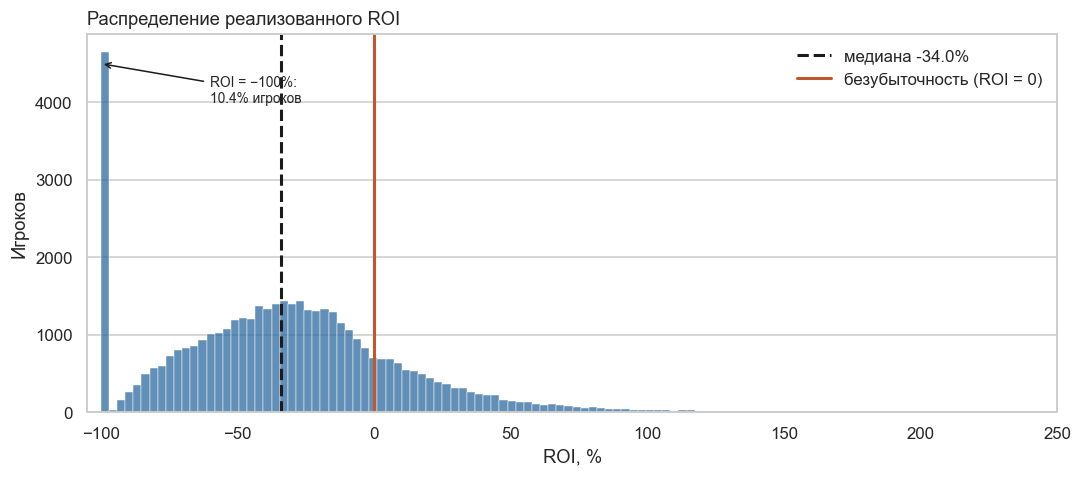

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.5))

sns.histplot(roi, bins=bins_fd, color=MAIN, edgecolor="white", linewidth=0.3, ax=ax)
ax.axvline(roi.median(), color="#1b1b1b", linewidth=2, linestyle="--",
           label=f"медиана {roi.median():.1f}%")
ax.axvline(0, color=ACCENT, linewidth=2, label="безубыточность (ROI = 0)")
ax.annotate(f"ROI = −100%:\n{(roi == -100).mean() * 100:.1f}% игроков", xy=(-100, 4500),
            xytext=(-60, 4000), arrowprops={"arrowstyle": "->", "color": "#1b1b1b"}, fontsize=9)
ax.set_xlim(-105, 250)
ax.set_title("Распределение реализованного ROI")
ax.set_xlabel("ROI, %")
ax.set_ylabel("Игроков")
ax.legend(frameon=False)

fig.tight_layout()
plt.show()

print("ROI > 0:", round((roi > 0).mean() * 100, 2), "% | ROI > 250 (вне окна графика):", int((roi > 250).sum()))

**Вывод.** ROI большинства игроков отрицателен, а распределение имеет длинный правый хвост.

#### График 2. ROI по уровню мастерства — *сравнение*

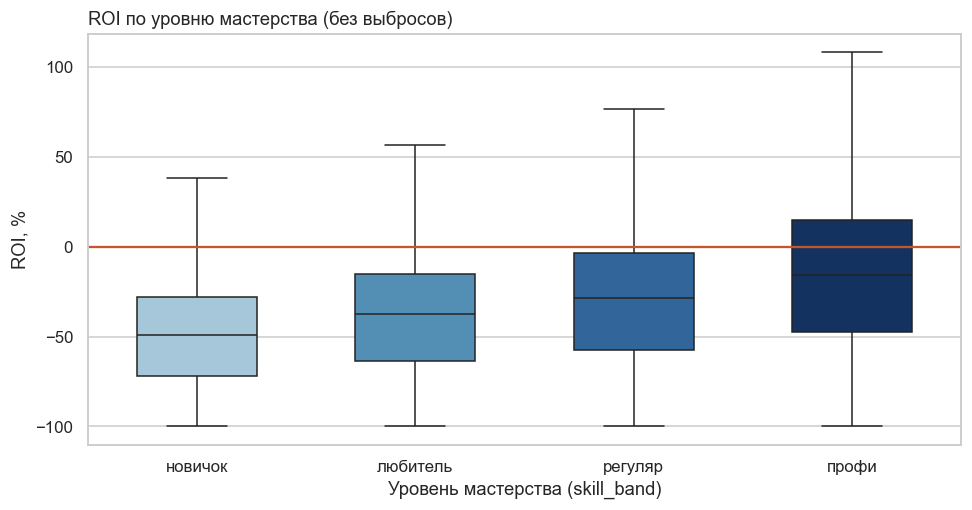

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.8))

sns.boxplot(data=df, x="skill_band", y="realized_roi", hue="skill_band", palette=SKILL_COLORS,
            legend=False, width=0.55, showfliers=False, ax=ax)
ax.axhline(0, color=ACCENT, linewidth=1.5)
ax.set_title("ROI по уровню мастерства (без выбросов)")
ax.set_xlabel("Уровень мастерства (skill_band)")
ax.set_ylabel("ROI, %")

fig.tight_layout()
plt.show()

print(df.groupby("skill_band", observed=True)["realized_roi"]
      .describe()[["25%", "50%", "75%", "std"]].round(1).to_string())

**Вывод.** С ростом мастерства распределение ROI смещается вверх.

#### График 3. ROI по мастерству и объёму — *сравнение*

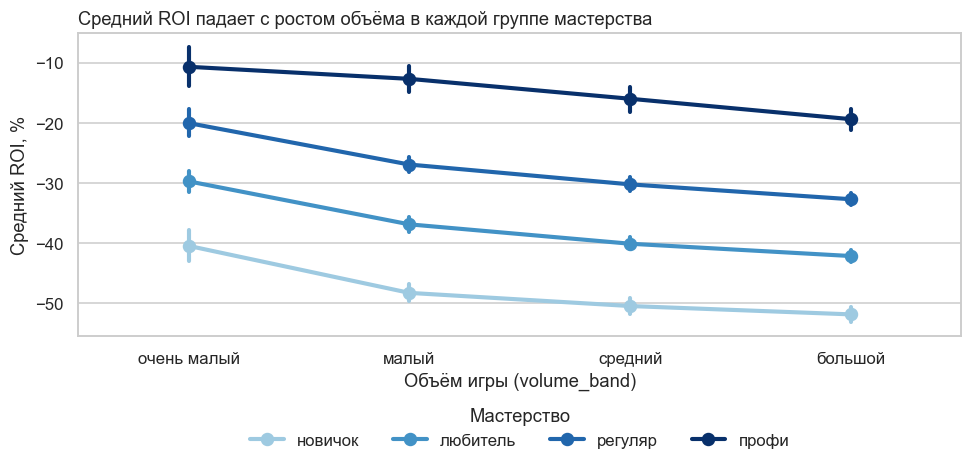

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.8))

sns.pointplot(data=df, x="volume_band", y="realized_roi", hue="skill_band", palette=SKILL_COLORS,
              estimator="mean", errorbar=("ci", 95), markers="o", ax=ax)
ax.set_title("Средний ROI падает с ростом объёма в каждой группе мастерства")
ax.set_xlabel("Объём игры (volume_band)")
ax.set_ylabel("Средний ROI, %")
ax.legend(title="Мастерство", frameon=False, ncols=4, loc="lower center", bbox_to_anchor=(0.5, -0.42))

fig.tight_layout()
plt.show()

**Вывод.** ROI зависит одновременно от мастерства и объёма игры.

#### График 4. Банкротство, банкролл и мастерство — *взаимосвязь*

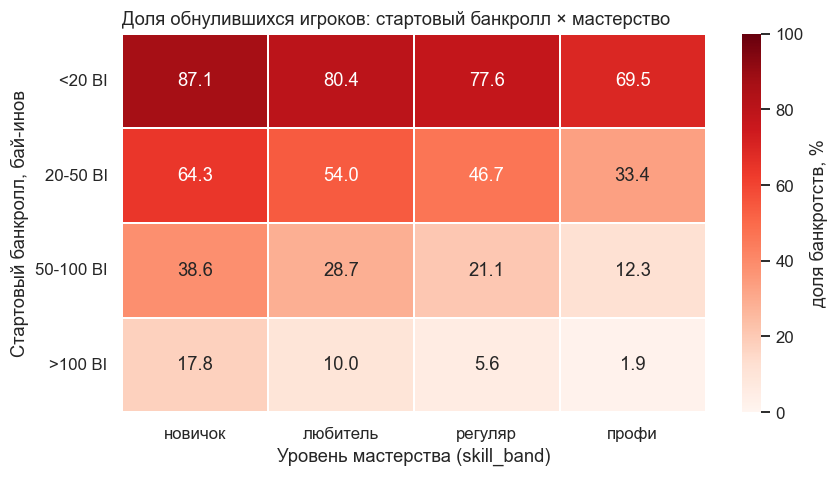

In [19]:
bankroll_band = pd.cut(df["bankroll_buyins"], [0, 20, 50, 100, np.inf],
                       labels=["<20 BI", "20-50 BI", "50-100 BI", ">100 BI"], right=False)
broke_matrix = pd.pivot_table(df.assign(bankroll_band=bankroll_band,
                                        broke=df["went_broke"].astype(int) * 100),
                              index="bankroll_band", columns="skill_band", values="broke",
                              aggfunc="mean", observed=True)

fig, ax = plt.subplots(figsize=(8, 4.5))

sns.heatmap(broke_matrix, annot=True, fmt=".1f", cmap="Reds", vmin=0, vmax=100,
            linewidths=1, linecolor="white", cbar_kws={"label": "доля банкротств, %"}, ax=ax)
ax.set_title("Доля обнулившихся игроков: стартовый банкролл × мастерство")
ax.set_xlabel("Уровень мастерства (skill_band)")
ax.set_ylabel("Стартовый банкролл, бай-инов")
ax.tick_params(axis="y", rotation=0)
ax.grid(False)

fig.tight_layout()
plt.show()

print("перепад по банкроллу (внутри столбцов):",
      (broke_matrix.iloc[0] - broke_matrix.iloc[-1]).round(1).to_dict())
print("перепад по мастерству (внутри строк):",
      (broke_matrix.iloc[:, 0] - broke_matrix.iloc[:, -1]).round(1).to_dict())

**Вывод.** Больший запас банкролла связан с меньшей долей банкротств.

#### График 5. Воронка дисперсии: объём и ROI — *взаимосвязь* (интерактивный)

In [20]:
funnel_df = df.sample(4000, random_state=6401).assign(skill_band=lambda d: d["skill_band"].astype(str))

fig_funnel = px.scatter(
    funnel_df, x="tournaments_played", y="realized_roi", color="skill_band", log_x=True,
    category_orders={"skill_band": ["новичок", "любитель", "регуляр", "профи"]},
    color_discrete_sequence=SKILL_COLORS, opacity=0.6,
    hover_name="player_id",
    hover_data={"skill": ":.2f", "itm_rate": ":.1f", "biggest_cash_x": ":.1f",
                "bankroll_buyins": True, "skill_band": False},
    labels={"tournaments_played": "Сыграно турниров (логарифмическая шкала)", "realized_roi": "ROI, %",
            "skill_band": "Мастерство", "itm_rate": "ITM, %", "biggest_cash_x": "крупнейший занос, x",
            "bankroll_buyins": "банкролл, BI"},
    title="Разброс ROI сужается с ростом дистанции",
    template="plotly_white", height=520,
)
fig_funnel.update_traces(marker={"size": 5})
fig_funnel.add_hline(y=0, line_color="#1b1b1b", line_width=1)
fig_funnel.show()

**Вывод.** На малой дистанции результаты игроков значительно более разбросаны.

#### График 6. Доля банкротств по группам мастерства и объёма — *сравнение* (интерактивный)

График из задания 2.3, с кнопками сортировки.

In [21]:
fig_bar.show()

**Вывод.** Доля банкротств различается по группам объёма и мастерства.

### Общее заключение

Мастерство, объём игры и размер банкролла связаны с ROI и риском банкротства.

## Контрольные вопросы

**1. В каком случае предпочтительнее использовать boxplot, а в каком — гистограмму?**
Гистограмма показывает форму распределения целиком: число мод, асимметрию, пики и провалы — например, пик у −100% в `realized_roi` виден только на гистограмме. Её выбирают, когда нужно понять устройство одного распределения. Boxplot сжимает распределение до пяти чисел (минимум уса, Q1, медиана, Q3, максимум уса) и отдельно отмечает выбросы. Он компактен, поэтому лучше подходит для сравнения распределений между несколькими группами на одном графике (ROI по четырём уровням мастерства) и для быстрого поиска выбросов, но скрывает многомодальность: два разных распределения могут иметь одинаковый boxplot.

**2. Почему круговые диаграммы считаются плохим выбором при большом числе категорий?**
Круговая диаграмма кодирует величину углом и площадью сектора, а человек сравнивает углы и площади гораздо хуже, чем длины на общей шкале. При большом числе категорий секторы становятся узкими и почти равными, несоседние доли сравнить невозможно, подписи накладываются, для различения нужно много цветов, а порядок категорий теряется. Круговая диаграмма уместна только для двух-трёх долей целого; в остальных случаях отсортированная столбчатая диаграмма передаёт то же точнее.

**3. Чем отличается архитектура Seaborn от Matplotlib (в чём Seaborn — надстройка)?**
Matplotlib — низкоуровневая библиотека: объекты `Figure` и `Axes`, на которые вручную наносятся линии, столбцы, точки, подписи; данные передаются массивами, а группировку, агрегацию и раскраску по категориям нужно делать самостоятельно. Seaborn построен поверх Matplotlib и рисует на тех же `Axes`, но работает на уровне статистических задач: принимает `DataFrame` и имена столбцов, сам группирует по `hue`, считает средние, доверительные интервалы, ядерные оценки плотности, строит легенды и задаёт согласованные темы. Результат Seaborn — обычный объект Matplotlib, поэтому его можно донастроить средствами Matplotlib, как в этой работе (`ax.set_xscale`, `ax.bar_label`).

**4. Какие преимущества даёт интерактивная визуализация (Plotly) по сравнению со статической при исследовательском анализе данных?**
Подсказки при наведении показывают значения нескольких признаков конкретного наблюдения без перегрузки графика подписями — так в задании 2.2 выброс опознаётся по `biggest_cash_x` и числу турниров. Масштабирование и панорамирование позволяют рассмотреть плотную область без перестроения графика, клик по легенде скрывает и показывает группы, кнопки меняют сортировку или представление. Один интерактивный график заменяет серию статических, и аналитик проверяет гипотезы быстрее. Ограничение — интерактивность не переносится в печатный отчёт, там нужна статическая версия.

**5. Что показывает тепловая карта корреляций и как трактовать значение, близкое к 0?**
Тепловая карта корреляций — матрица попарных коэффициентов корреляции признаков, где цвет кодирует знак и силу связи; она позволяет одним взглядом найти сильно связанные пары, мультиколлинеарность и блоки признаков. Значение около 0 означает отсутствие **линейной** связи, но не отсутствие связи вообще: зависимость может быть нелинейной или проявляться в разбросе, а не в среднем. Пример из этого набора: корреляция `tournaments_played` и `realized_roi` равна −0.077, хотя объём вдвое сужает разброс ROI. Кроме того, корреляция не означает причинности: сильные связи `itm_rate` и `realized_roi` описывают один и тот же исход, а не причину и следствие.

**6. Приведите пример, когда визуализация может ввести в заблуждение, даже если данные на графике корректны.**
Пример из задания 2.1: доли банкротств 49.2%, 49.5% и 51.6% на столбчатой диаграмме с осью Y от 49% выглядят как различие в разы, хотя оно составляет 2.4 п.п. Другие примеры: сравнение средних без учёта размера групп (у хайроллеров всего 179 игроков, и их «худший ROI» может быть шумом); выбор окна оси X, отрезающего хвост распределения; разные масштабы осей на соседних графиках; средний ROI по короткой дистанции, который из-за survivorship bias выглядит лучше длинной, хотя игроки там не сильнее.